# Steam Game Recommendation System and Clustering

27,000 games on the Steam store, each with a description and the tags its players voted for. Given one game you like, which
others should you try? This notebook builds content-based recommenders from two different signals (what the developer **writes**
and what players **tag**), measures them against a popularity baseline without any user data, re-ranks them by quality, and groups
the whole catalogue into clusters you can name.

**Objectives**
1. What does the Steam catalogue look like, and how do we rank games by quality fairly?
2. How do we turn descriptions and tags into vectors (text normalization, Count vs TF-IDF)?
3. How do cosine similarity and the linear kernel find similar games, and when are they the same?
4. Without user histories, how can we tell whether recommendations are good?
5. Which signal recommends better: descriptions, tags, or both?
6. Can a quality score fix the recommender's taste for obscure games without drowning it in hits?
7. Which natural groups of games exist, and how many?

**Data** → [Kaggle dataset nikdavis/steam-store-games](https://www.kaggle.com/datasets/nikdavis/steam-store-games) · 27,075 games · store data up to May 2019

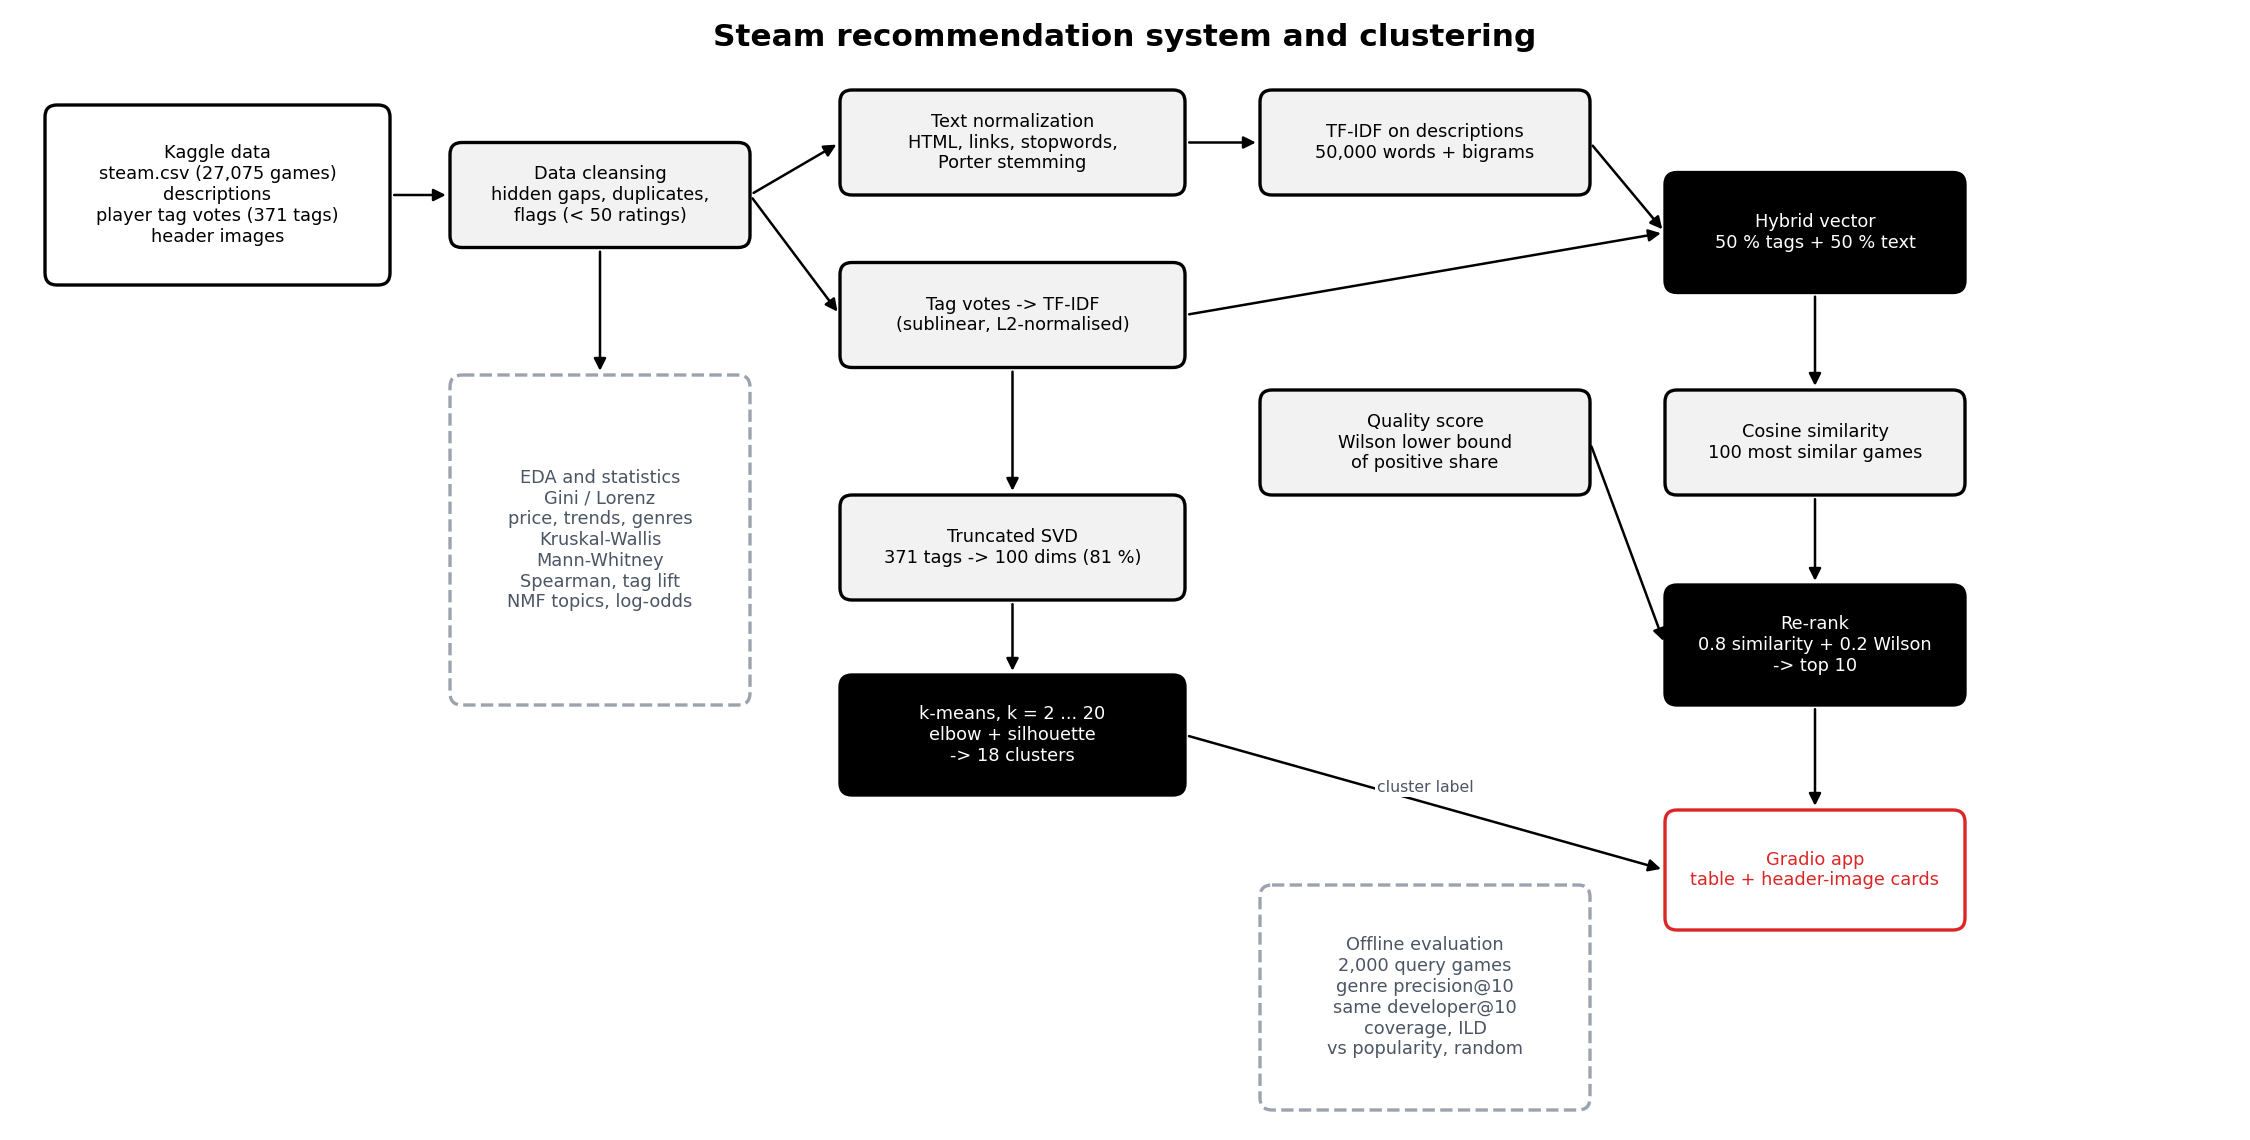

# [1/20] Setup

Set every knob once in the top cell → later cells only read them, and nothing is written unless `SAVE_FIGURES = True`

In [ ]:
"""Optional · Edit the settings, then run all cells. Explanations: README.md

[1/11] DATA_DIR: dataset folder (searched recursively for steam.csv if not found here)
    Default = '/kaggle/input/datasets/nikdavis/steam-store-games'
[2/11] WORK_DIR: folder for exported figures
    Default = '/kaggle/working'
[3/11] SEED: random seed
    Default = 42
[4/11] TOP_K: recommendations per game
    Default = 10
[5/11] MIN_RATINGS: a game needs at least this many ratings to be used as an evaluation query
    Default = 50
[6/11] N_QUERIES: games sampled as evaluation queries
    Default = 2000
[7/11] HYBRID_WEIGHT: weight of the tag signal in the hybrid (0 = descriptions only, 1 = tags only)
    Default = 0.5
[8/11] QUALITY_WEIGHTS: weights of the quality score tried when re-ranking
    Default = (0, 0.1, 0.2, 0.3, 0.5)
[9/11] K_RANGE: numbers of clusters tried
    Default = 2 ... 20
[10/11] SAVE_FIGURES: write every chart to WORK_DIR/assets
    Default = False
    For example:
        SAVE_FIGURES = True
[11/11] LAUNCH_APP: start the Gradio recommendation app at the end (needs Internet; prints a public link)
    Default = False
"""
DATA_DIR        = '/kaggle/input/datasets/nikdavis/steam-store-games'
WORK_DIR        = '/kaggle/working'
SEED            = 42
TOP_K           = 10
MIN_RATINGS     = 50
N_QUERIES       = 2000
HYBRID_WEIGHT   = 0.5
QUALITY_WEIGHTS = (0, 0.1, 0.2, 0.3, 0.5)
K_RANGE         = range(2, 21)
SAVE_FIGURES    = False
LAUNCH_APP      = False

EXAMPLE_GAMES    = ['Portal 2', 'Stardew Valley', 'Cities: Skylines', 'DARK SOULS™ III', 'Counter-Strike: Global Offensive']
WILSON_Z         = 1.96                  # 95 % confidence for the Wilson lower bound
TEXT_MIN_DF      = 5                     # a word must appear in at least 5 descriptions
TEXT_MAX_DF      = 0.5                   # ... and in at most half of them
TEXT_MAX_FEAT    = 50_000
SVD_COMPONENTS   = 100                   # tag vectors are compressed to 100 dimensions before clustering
SILHOUETTE_N     = 5000                  # games sampled to compute the silhouette score
TSNE_N           = 5000                  # games shown in the 2-D map
BATCH            = 500                   # queries scored per batch (keeps memory small)
N_TOPICS         = 12                    # topics extracted from the descriptions (NMF)
PRIOR_SCALE      = 0.1                   # strength of the background prior in the log-odds word test
PAD              = 32
PALETTE          = {'main': 'black', 'flag': 'red', 'soft': 'grey'}
MIN_GROUP        = 200                   # smallest group (genre, tag, price band) used in quality comparisons
N_CARDS          = 10                    # header-image cards per recommendation

In [ ]:
import io
import re
import html
import subprocess
import sys
from concurrent.futures import ThreadPoolExecutor
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy import sparse, stats
import requests
from PIL import Image

from nltk.stem import PorterStemmer
from sklearn.cluster import KMeans
from sklearn.decomposition import NMF, TruncatedSVD
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfTransformer, TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity, linear_kernel
from sklearn.preprocessing import normalize

warnings.filterwarnings('ignore')
sns.set_style('darkgrid')
sns.set_palette('gray')
rng = np.random.default_rng(SEED)
ASSETS = Path(WORK_DIR) / 'assets'
if SAVE_FIGURES:
    ASSETS.mkdir(parents=True, exist_ok=True)

In [ ]:
def show_block(title, items):
    print(f'{title}:')
    for key, value in items.items():
        print(f'    {key:<{PAD}}{value}')


def save(fig, name):
    if SAVE_FIGURES:
        fig.savefig(ASSETS / f'{name}.png', bbox_inches='tight', dpi=110)


def find_data_dir(default, root='/kaggle/input'):
    """Folder that holds steam.csv (with a steamspy_tags column). Tries `default`, then searches `root`."""
    import csv
    candidates = [Path(default)]
    if Path(root).exists():
        candidates += sorted(p.parent for p in Path(root).rglob('steam.csv'))
    for folder in candidates:
        if (folder / 'steam.csv').is_file():
            with open(folder / 'steam.csv', newline='', encoding='utf-8') as fh:
                if 'steamspy_tags' in next(csv.reader(fh)):
                    return folder
    mounted = sorted(str(p) for p in Path(root).glob('*/*'))[:20] if Path(root).exists() else []
    raise FileNotFoundError(f'(!) No steam.csv under {default} or {root}.\n'
                            f'    Add Input -> Datasets -> nikdavis/steam-store-games\n'
                            f'    Mounted now: {mounted or "nothing"}')

# [2/20] Data

Load the store table, the descriptions and the player tag votes, and align them on the game id → one row per game

In [ ]:
data_dir = find_data_dir(DATA_DIR)
store = pd.read_csv(data_dir / 'steam.csv')
descriptions = pd.read_csv(data_dir / 'steam_description_data.csv').rename(columns={'steam_appid': 'appid'})
tag_votes = pd.read_csv(data_dir / 'steamspy_tag_data.csv')
media = pd.read_csv(data_dir / 'steam_media_data.csv', usecols=['steam_appid', 'header_image']).rename(columns={'steam_appid': 'appid'})

games = (store.merge(descriptions[['appid', 'short_description', 'about_the_game']], on='appid', how='inner')
              .merge(tag_votes[['appid']], on='appid', how='inner')
              .merge(media, on='appid', how='left')
              .drop_duplicates('appid').reset_index(drop=True))
tag_matrix_df = tag_votes.set_index('appid').loc[games['appid']]
TAGS = tag_matrix_df.columns.tolist()
show_block('Inputs', {'data folder': data_dir, 'steam.csv': store.shape, 'descriptions': descriptions.shape,
                      'tag votes': tag_votes.shape})

In [ ]:
show_block('Outputs', {'games (all three sources)': len(games), 'tags': len(TAGS),
                       'games with no tag votes': int((tag_matrix_df.sum(axis=1) == 0).sum()),
                       'duplicate names (different ids)': int(games['name'].duplicated().sum())})
display(games[['appid', 'name', 'release_date', 'developer', 'genres', 'steamspy_tags', 'positive_ratings',
               'negative_ratings', 'owners', 'price']].head())

**Question:** What is in the data, and what has to be fixed before modelling?

**Answer:** little — all 27,075 games have a description and tag votes (371 tags).
To convert: `owners` bands → lower bound; positive / negative counts → total ratings and a quality score.

In [ ]:
games['release_year'] = pd.to_datetime(games['release_date'], errors='coerce').dt.year
games['ratings'] = games['positive_ratings'] + games['negative_ratings']
games['owners_low'] = games['owners'].str.split('-').str[0].astype(int)
games['owners_mid'] = games['owners'].str.split('-').apply(lambda b: (int(b[0]) + int(b[1])) / 2)
games['genre_set'] = games['genres'].fillna('').str.split(';').apply(lambda g: frozenset(x for x in g if x))
display(pd.DataFrame({'missing': games[['developer', 'publisher', 'genres', 'short_description', 'about_the_game']].isna().sum()}))
display(games['owners'].value_counts().rename('games').to_frame().head(13))

# [3/20] Data cleansing

Check every column for duplicates, gaps, impossible values and hidden "unknowns" → fix or flag each one, and keep a log of what changed

**Question:** What is dirty in the data, and what should be done about each problem?

- **Rule** → never delete a game just because one column is imperfect: the recommender should still be able to suggest it
- **Hidden missing values** → a playtime of 0 minutes usually means "no data", not "nobody played": it is turned into a real gap (NaN)
- **Flags instead of deletion** → games with too few ratings stay in the catalogue but are left out of quality comparisons
- Analogy → cleaning a library catalogue: fix typos and mark missing authors, but do not throw books away

**Answer:** clean structure, hidden gaps; no game deleted.
- 77 % report 0 minutes playtime = no data → set to missing, not zero
- 15,257 games with < 50 ratings → excluded only from quality comparisons
- 11 products over \$100 are real tools (GameMaker, Houdini) → kept

In [ ]:
log = []


def note(issue, rows, action):
    log.append({'issue': issue, 'rows': int(rows), 'action': action})


note('duplicate appid', games['appid'].duplicated().sum(), 'none found')
note('same name, different appid', games['name'].duplicated(keep=False).sum(),
     'kept (re-releases / regional editions); recommendations exclude the query game only')
games['name'] = games['name'].str.strip()

bad_date = games['release_year'].isna()
note('release date not parseable', bad_date.sum(), 'kept; excluded from yearly trends')

for col in ['developer', 'publisher']:
    note(f'missing {col}', games[col].isna().sum(), "filled with 'unknown'")
    games[col] = games[col].fillna('unknown').str.strip()

note('not available in English (english = 0)', (games['english'] == 0).sum(),
     'kept; their descriptions may be empty after English text cleaning, tags still describe them')

zero_play = games['average_playtime'] == 0
note('average playtime = 0 (no data)', zero_play.sum(), 'set to NaN (unknown), not zero hours')
games.loc[zero_play, ['average_playtime', 'median_playtime']] = np.nan

high_price = games['price'] > 100
note('price above $100', high_price.sum(), 'checked: real software / bundles; kept, clipped only in charts')

few = games['ratings'] < MIN_RATINGS
note(f'fewer than {MIN_RATINGS} ratings', few.sum(), 'kept for recommending; excluded from quality comparisons')

no_genre = games['genre_set'].apply(len) == 0
note('no genre', no_genre.sum(), 'kept; tags still describe the game')

for col in ['genres', 'steamspy_tags', 'categories', 'platforms']:
    games[col] = games[col].fillna('').str.replace(r'\s*;\s*', ';', regex=True).str.strip(';')

cleaning_log = pd.DataFrame(log).set_index('issue')

In [ ]:
display(cleaning_log)
display(games.loc[high_price, ['name', 'price', 'genres', 'ratings']].sort_values('price', ascending=False).head(6))
show_block('After cleansing', {'games': len(games), 'columns': games.shape[1],
                               f'games usable for quality analysis (>= {MIN_RATINGS} ratings)': int((~few).sum())})

# [4/20] The catalogue

Count games per year, genre and owner band → the catalogue is young, indie-heavy and extremely unequal

In [ ]:
genre_counts = pd.Series([g for s in games['genre_set'] for g in s]).value_counts()
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
games['release_year'].value_counts().sort_index().loc[2000:2019].plot.bar(ax=axes[0], color=PALETTE['main'])
axes[0].set(title='Games released per year', xlabel='')
genre_counts.head(12).sort_values().plot.barh(ax=axes[1], color=PALETTE['main'])
axes[1].set(title='Most common genres')
order = games.groupby('owners')['owners_low'].first().sort_values().index
games['owners'].value_counts().reindex(order).plot.bar(ax=axes[2], color=PALETTE['main'])
axes[2].set(title='Games per owner band', xlabel='owners', yscale='log')
axes[2].tick_params(axis='x', rotation=60)
fig.tight_layout()
save(fig, '01_catalogue')
plt.show()

In [ ]:
show_block('Catalogue', {'released 2014 or later': f"{(games['release_year'] >= 2014).mean():.1%}",
                         'tagged Indie': f"{(genre_counts.get('Indie', 0) / len(games)):.1%}",
                         'below 20,000 owners': f"{(games['owners_low'] == 0).mean():.1%}",
                         'games with 0 ratings': int((games['ratings'] == 0).sum()),
                         'median ratings per game': int(games['ratings'].median())})

**Question:** What kind of catalogue are we recommending from?

**Answer:** young, indie and long-tailed: 93.2 % released since 2014, 71.7 % Indie, 68.7 % under 20,000 owners, median 36 ratings.
→ popularity would show everyone the same few hits.

# [5/20] A fair quality score

Rank games by the share of positive reviews, corrected for how many reviews they have → the Wilson lower bound

**Question:** Is a game with 5 positive reviews out of 5 better than one with 9,500 out of 10,000?

$$\text{Wilson}(p, n) = \frac{\hat p + \frac{z^2}{2n} - z\sqrt{\frac{\hat p(1-\hat p)}{n} + \frac{z^2}{4n^2}}}{1 + \frac{z^2}{n}}$$
- $\hat p$ → share of positive ratings, $n$ → number of ratings, $z = 1.96$ → 95 % confidence
- the result is the **lowest** positive share we can be 95 % sure of: few reviews → wide uncertainty → low score
- Analogy → a restaurant with one 5-star review vs one with 2,000 reviews averaging 4.7: the second is the safer bet

**Answer:** no — 5/5 scores 0.566, 9,500/10,000 scores 0.946.
Wilson puts *Portal 2* and *Factorio* on top instead of obscure games with 100 perfect reviews.

In [ ]:
def wilson(pos, n, z=WILSON_Z):
    n = np.asarray(n, dtype=float)
    p = np.divide(pos, n, out=np.zeros_like(n), where=n > 0)
    centre = p + z ** 2 / (2 * n.clip(min=1))
    margin = z * np.sqrt(p * (1 - p) / n.clip(min=1) + z ** 2 / (4 * n.clip(min=1) ** 2))
    return np.where(n > 0, (centre - margin) / (1 + z ** 2 / n.clip(min=1)), 0.0)


games['positive_share'] = games['positive_ratings'] / games['ratings'].replace(0, np.nan)
games['wilson'] = wilson(games['positive_ratings'], games['ratings'])
examples = pd.DataFrame({'positive': [5, 9500, 90], 'ratings': [5, 10000, 100]})
examples['positive share'] = examples['positive'] / examples['ratings']
examples['wilson'] = wilson(examples['positive'], examples['ratings'])
display(examples.round(3))

In [ ]:
cols = ['name', 'positive_ratings', 'negative_ratings', 'positive_share', 'wilson']
display(pd.concat({'top by positive share': games.sort_values(['positive_share', 'ratings'], ascending=False)[cols].head(5).reset_index(drop=True),
                   'top by Wilson': games.sort_values('wilson', ascending=False)[cols].head(5).reset_index(drop=True)}).round(3))

# [6/20] Who gets the players? Market concentration

Draw the Lorenz curve of ratings and owners and count games per developer → a few games take almost all the attention

**Question:** How unequal is the attention games receive?

$$G = \frac{\sum_{i=1}^{n}(2i - n - 1)\,x_{(i)}}{n \sum_{i} x_{(i)}}$$
- $x_{(i)}$ → the $i$-th smallest value (ratings or owners of a game); $G = 0$ → every game equally popular, $G = 1$ → one game has everything
- **Lorenz curve** → share of all ratings held by the bottom $p$ % of games; the further it sags below the diagonal, the more unequal
- ratings are used as a proxy for players (owners are only known in wide bands)
- Analogy → income inequality in a country, with games as people and ratings as income

**Answer:** attention is extremely concentrated, quality is not.
- Gini 0.944: top 1 % of games hold 63.8 % of ratings, the bottom half 0.51 %
- prolific developers (5+ games) are not better reviewed (0.776 vs 0.780, p = 0.32)

In [ ]:
def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    return float(((2 * np.arange(1, n + 1) - n - 1) * x).sum() / (n * x.sum()))


def lorenz(x):
    x = np.sort(np.asarray(x, dtype=float))
    return np.linspace(0, 1, len(x) + 1), np.concatenate([[0], np.cumsum(x) / x.sum()])


top1 = games['ratings'].sort_values(ascending=False)
dev_counts = games['developer'].fillna('unknown').value_counts()
games['developer_games'] = games['developer'].map(dev_counts).fillna(1)
rated = games[games['ratings'] >= MIN_RATINGS].copy()
dev_group = np.where(rated['developer_games'] >= 5, '5+ games', np.where(rated['developer_games'] >= 2, '2-4 games', '1 game'))
dev_quality = rated.groupby(dev_group)['positive_share'].agg(['median', 'size'])
mw_dev = stats.mannwhitneyu(rated.loc[dev_group == '5+ games', 'positive_share'], rated.loc[dev_group == '1 game', 'positive_share'])

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for col, c in [('ratings', PALETTE['main']), ('owners_mid', PALETTE['flag'])]:
    p, l = lorenz(games[col])
    axes[0].plot(p, l, color=c, label=f'{col} (Gini {gini(games[col]):.2f})')
axes[0].plot([0, 1], [0, 1], color=PALETTE['soft'], ls='--')
axes[0].set(title='Lorenz curve', xlabel='share of games (least to most popular)', ylabel='share of total')
axes[0].legend()
dev_counts.head(15).sort_values().plot.barh(ax=axes[1], color=PALETTE['main'])
axes[1].set(title='Most prolific developers (games in the catalogue)')
fig.tight_layout()
save(fig, '02_concentration')
plt.show()

In [ ]:
show_block('Concentration', {
    'Gini of ratings': round(gini(games['ratings']), 3),
    'Gini of owners (band midpoints)': round(gini(games['owners_mid']), 3),
    'ratings held by top 1 % of games': f"{top1.head(len(games) // 100).sum() / top1.sum():.1%}",
    'ratings held by top 10 % of games': f"{top1.head(len(games) // 10).sum() / top1.sum():.1%}",
    'ratings held by bottom 50 %': f"{top1.tail(len(games) // 2).sum() / top1.sum():.2%}",
    'developers': len(dev_counts),
    'developers with a single game': f"{(dev_counts == 1).mean():.1%}",
})
display(dev_quality.rename(columns={'median': 'median positive share', 'size': f'games with >= {MIN_RATINGS} ratings'}).round(3))
print(f'Mann-Whitney U, 5+ games vs 1 game: p = {mw_dev.pvalue:.2e}')

# [7/20] Price and free-to-play

Compare free and paid games and price bands on quality and attention → paying more does not buy better reviews

**Question:** Are expensive games better reviewed, and do free games get more players?

$$\rho_s = 1 - \frac{6 \sum d_i^2}{n(n^2 - 1)}$$
- **Spearman** $\rho_s$ → correlation of the *ranks* ($d_i$ = rank difference), robust to the skewed price and rating distributions
- **Mann-Whitney U** → do free and paid games have the same distribution of positive share? ($H_0$: yes)
- quality comparisons use games with at least 50 ratings, where the positive share is reliable
- Analogy → asking whether expensive restaurants get better reviews, using rankings instead of raw prices

**Answer:** a little, not linearly (Spearman 0.156).
- \$10–20 reviews best (0.816); free games worst (0.738, p = 1.5e-12)
- free games get more ratings than cheap ones (87 vs 21) — players, but harsher reviews

In [ ]:
PRICE_BANDS = [-0.01, 0, 5, 10, 20, 40, 1000]
PRICE_LABELS = ['free', '0-5', '5-10', '10-20', '20-40', '40+']
games['price_band'] = pd.cut(games['price'], PRICE_BANDS, labels=PRICE_LABELS)
rated = games[games['ratings'] >= MIN_RATINGS].copy()
price_table = games.groupby('price_band', observed=True).agg(games=('appid', 'size'), median_ratings=('ratings', 'median'))
price_table['median positive share (rated)'] = rated.groupby('price_band', observed=True)['positive_share'].median()
rho_price = stats.spearmanr(rated['price'], rated['positive_share'])
rho_price_ratings = stats.spearmanr(games['price'], games['ratings'])
mw_free = stats.mannwhitneyu(rated.loc[rated['price'] == 0, 'positive_share'], rated.loc[rated['price'] > 0, 'positive_share'])

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
games.loc[games['price'] > 0, 'price'].clip(upper=60).plot.hist(bins=60, ax=axes[0], color=PALETTE['main'])
axes[0].set(title='Price of paid games (clipped at $60)', xlabel='USD')
sns.boxplot(data=rated, x='price_band', y='positive_share', color='lightgrey', showfliers=False, ax=axes[1])
axes[1].set(title=f'Positive share by price band (games with >= {MIN_RATINGS} ratings)', xlabel='price band (USD)')
fig.tight_layout()
save(fig, '03_price')
plt.show()

In [ ]:
show_block('Price', {'free games': f"{(games['price'] == 0).mean():.1%}",
                     'median price of paid games': f"${games.loc[games['price'] > 0, 'price'].median():.2f}",
                     'Spearman price vs positive share': f'{rho_price.statistic:.3f} (p = {rho_price.pvalue:.1e})',
                     'Spearman price vs ratings': f'{rho_price_ratings.statistic:.3f}',
                     'free vs paid positive share, p': f'{mw_free.pvalue:.1e}'})
display(price_table.round(3))

# [8/20] Trends over time

Follow releases, price, attention and quality per release year → the store floods, and each game gets a smaller slice

**Question:** How has the Steam store changed from 2006 to 2018?

**Answer:** the store flooded: releases ×170 (48 → 8,160), median ratings per game 504 → 15, median price \$5.99 → \$3.99.
(!) The 2018 quality rebound is partly selection (only successful games reach 50 ratings).

In [ ]:
years = games[games['release_year'].between(2006, 2018)]
trend = years.groupby('release_year').agg(games=('appid', 'size'), median_ratings=('ratings', 'median'),
                                          median_price=('price', 'median'), free_share=('price', lambda p: (p == 0).mean()))
trend['median positive share (rated)'] = rated[rated['release_year'].between(2006, 2018)].groupby('release_year')['positive_share'].median()

fig, axes = plt.subplots(1, 4, figsize=(22, 4.2))
for ax, (col, title) in zip(axes, [('games', 'Games released'), ('median_ratings', 'Median ratings per game'),
                                   ('median_price', 'Median price (USD)'), ('median positive share (rated)', 'Median positive share')]):
    ax.plot(trend.index, trend[col], marker='o', color=PALETTE['flag'] if col == 'games' else PALETTE['main'])
    ax.set(title=title, xlabel='')
axes[0].set_yscale('log')
axes[1].set_yscale('log')
fig.tight_layout()
save(fig, '04_trends')
plt.show()

In [ ]:
display(trend.loc[[2006, 2010, 2014, 2016, 2018]].round(3))

# [9/20] Genres and tags

Rank genres and player tags by review quality and find which tags travel together → niches beat mainstream labels

**Question:** Which genres and tags go with the best reviews, and which tags appear together?

$$\text{lift}(a, b) = \frac{P(a \cap b)}{P(a)\,P(b)}$$
- **Kruskal-Wallis H** → do the genres share one distribution of positive share? ($H_0$: yes)
- **Tag effect** → median positive share of games carrying a tag minus the overall median (tags on at least 200 rated games)
- **Lift** → how much more often two tags appear together than if they were independent: 1 = no relation, 5 = five times more often
- Analogy → market-basket analysis: bread and butter are bought together far more than chance

**Answer:** niche, single-player, story and style win; online and survival lose.
- genres differ (Kruskal-Wallis p ≈ 4e-119): Indie 0.791 … Massively Multiplayer 0.646
- best tags: cute, visual novel, bullet hell, great soundtrack (+0.08 to +0.11); worst: MMO −0.126, PvP, crafting, survival
- tags that travel together: anime + female protagonist (lift 4.97), 2D + pixel graphics (4.74)

In [ ]:
genre_rows = []
for g in genre_counts.index:
    members = rated[rated['genre_set'].apply(lambda s, g=g: g in s)]
    if len(members) >= MIN_GROUP:
        genre_rows.append({'genre': g, 'rated games': len(members), 'median positive share': members['positive_share'].median()})
genre_quality = pd.DataFrame(genre_rows).set_index('genre').sort_values('median positive share', ascending=False)
kw = stats.kruskal(*[rated[rated['genre_set'].apply(lambda s, g=g: g in s)]['positive_share'] for g in genre_quality.index])

has_tag = pd.DataFrame(tag_matrix_df.to_numpy() > 0, columns=TAGS, index=games.index)
rated_tags = has_tag.loc[rated.index]
overall_median = rated['positive_share'].median()
tag_rows = [{'tag': t, 'rated games': int(rated_tags[t].sum()),
             'effect (median - overall)': rated.loc[rated_tags[t], 'positive_share'].median() - overall_median}
            for t in TAGS if rated_tags[t].sum() >= MIN_GROUP]
tag_effect = pd.DataFrame(tag_rows).set_index('tag').sort_values('effect (median - overall)')

top_tags = has_tag.sum().sort_values(ascending=False).index[:25]
P = has_tag[top_tags].to_numpy(dtype=float)
p_single = P.mean(axis=0)
lift = (P.T @ P / len(P)) / np.outer(p_single, p_single)
np.fill_diagonal(lift, np.nan)
lift_df = pd.DataFrame(lift, index=top_tags, columns=top_tags)
pairs = (lift_df.where(np.triu(np.ones(lift.shape), 1).astype(bool)).stack().sort_values(ascending=False)
         .rename('lift').reset_index().rename(columns={'level_0': 'tag A', 'level_1': 'tag B'}))

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
both = pd.concat([tag_effect.head(10), tag_effect.tail(10)])
axes[0].barh(both.index, both['effect (median - overall)'],
             color=[PALETTE['flag'] if v < 0 else PALETTE['main'] for v in both['effect (median - overall)']])
axes[0].axvline(0, color=PALETTE['soft'])
axes[0].set(title='Tags with the best and worst reviews (median positive share vs overall)')
sns.heatmap(np.log2(lift_df), cmap='RdGy_r', center=0, ax=axes[1], cbar_kws={'label': 'log2 lift'})
axes[1].set(title='How often the 25 most common tags appear together (log2 lift)')
fig.tight_layout()
save(fig, '05_tags')
plt.show()

In [ ]:
print(f'Kruskal-Wallis across {len(genre_quality)} genres: H = {kw.statistic:.1f}, p = {kw.pvalue:.1e}  |  overall median positive share {overall_median:.3f}')
display(genre_quality.round(3))
display(pd.concat({'best tags': tag_effect.tail(8)[::-1].reset_index(), 'worst tags': tag_effect.head(8).reset_index()}, axis=1).round(3))
display(pairs.head(8).round(2))

# [10/20] Engagement: playtime, achievements, platforms, descriptions

Correlate quality with how long people play, achievements, platform support and description length → effort signals go with better reviews

**Question:** Which measurable traits go together with well-reviewed games?

**Answer:** effort signals go with better reviews, description length does not (Spearman 0.004).
- Win + Mac + Linux 0.828 vs Windows only 0.753; achievements 0.800 vs 0.738
- (!) correlation, not cause — bigger studios do all of these

In [ ]:
rated = games[games['ratings'] >= MIN_RATINGS].copy()
rated['n_platforms'] = rated['platforms'].str.count(';') + 1
rated['has_achievements'] = rated['achievements'] > 0
rated['description_words'] = (rated['short_description'].fillna('') + ' ' + rated['about_the_game'].fillna('')).str.split().str.len()
features = {'log ratings': np.log1p(rated['ratings']), 'price': rated['price'], 'average playtime': rated['average_playtime'],
            'achievements': rated['achievements'], 'platforms': rated['n_platforms'], 'description words': rated['description_words'],
            'release year': rated['release_year']}
engage = pd.DataFrame({name: {'Spearman with positive share': stats.spearmanr(v, rated['positive_share'], nan_policy='omit').statistic}
                       for name, v in features.items()}).T.sort_values('Spearman with positive share')
platform_table = rated.groupby('n_platforms')['positive_share'].agg(['median', 'size'])
ach_table = rated.groupby('has_achievements')['positive_share'].agg(['median', 'size'])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(engage.index, engage['Spearman with positive share'],
        color=[PALETTE['flag'] if v < 0 else PALETTE['main'] for v in engage['Spearman with positive share']])
ax.axvline(0, color=PALETTE['soft'])
ax.set(title=f'Spearman correlation with positive share (games with >= {MIN_RATINGS} ratings)')
save(fig, '06_engagement')
plt.show()

In [ ]:
display(engage.round(3))
display(pd.concat({'by number of platforms': platform_table, 'by achievements': ach_table}).round(3))
show_block('Playtime', {'rated games with no playtime data': f"{rated['average_playtime'].isna().mean():.1%}",
                        'median average playtime where known (hours)': round(float(rated['average_playtime'].median()) / 60, 1)})

# [11/20] Text normalization

Clean each description before counting words: strip HTML, lowercase, drop punctuation and stopwords, stem → fewer, more meaningful tokens

**Question:** Why normalize text, and what does each step do?

- **HTML / entities / links** → descriptions are store pages: `<br>`, `&quot;`, image tags and URLs (store and social links) are noise
- **Lowercase + punctuation** → "Shooter", "shooter," and "SHOOTER!" become one token
- **Stopwords** → "the", "and", "you" appear everywhere and say nothing about a game (scikit-learn's list of 318 English words)
- **Stemming (Porter)** → "build", "builds", "building" → `build`; crude but language-agnostic
- Analogy → sorting a library by topic: you ignore the font, the capital letters and the word "the" on every cover

**Answer:** it halves the text (250 → 115 tokens) and the vocabulary shrinks 89,918 → 60,835.
29 non-English descriptions become empty; their tags still describe them.

In [ ]:
STEMMER = PorterStemmer()
TOKEN = re.compile(r'[a-z][a-z0-9]+')
STOP = set(ENGLISH_STOP_WORDS)
TAG_RE = re.compile(r'<[^>]+>')
URL_RE = re.compile(r'https?://\S+|www\.\S+|\S+\.(?:com|net|org)\S*')


def normalize_text(text):
    text = URL_RE.sub(' ', html.unescape(TAG_RE.sub(' ', str(text)))).lower()
    return ' '.join(STEMMER.stem(w) for w in TOKEN.findall(text) if w not in STOP)


raw_text = (games['short_description'].fillna('') + ' ' + games['about_the_game'].fillna(''))
games['clean_text'] = raw_text.map(normalize_text)
sample_i = games.index[games['name'] == 'Portal 2'][0]
show_block('Example: Portal 2', {'raw characters': len(raw_text[sample_i]),
                                 'clean tokens': len(games.loc[sample_i, 'clean_text'].split())})
print(raw_text[sample_i][:300], '...\n')
print(games.loc[sample_i, 'clean_text'][:300], '...')

In [ ]:
raw_tokens = raw_text.str.lower().str.findall(r'[a-z]+').map(len)
clean_tokens = games['clean_text'].str.split().map(len)
show_block('Effect of normalization', {'median tokens raw': int(raw_tokens.median()),
                                       'median tokens clean': int(clean_tokens.median()),
                                       'vocabulary raw': len(set(w for t in raw_text.str.lower().str.findall(r'[a-z]+') for w in t)),
                                       'vocabulary clean': len(set(w for t in games['clean_text'].str.split() for w in t)),
                                       'empty after cleaning': int((clean_tokens == 0).sum())})

# [12/20] Vectors: Count vs TF-IDF, text vs tags

Turn every game into a vector three ways → word counts, TF-IDF word weights, and TF-IDF weighted player tag votes

**Question:** How does TF-IDF decide which words matter?

$$\text{tfidf}(w, d) = \text{tf}(w, d) \cdot \log\frac{1 + N}{1 + \text{df}(w)} + 1 \qquad\qquad \vec v_d \leftarrow \frac{\vec v_d}{\lVert \vec v_d \rVert_2}$$
- $\text{tf}(w, d)$ → how often word $w$ appears in game $d$ (here $1 + \log \text{tf}$, so 50 mentions are not 50× one mention)
- $\text{df}(w)$ → in how many of the $N$ games it appears: a word in every description gets a weight near the minimum
- **Count** vectors keep raw counts → long descriptions and common words dominate
- **Tags** → the same idea applied to player votes: a game with 2,000 "Roguelike" votes is very roguelike, and a tag on every game ("Indie") counts less
- Analogy → a keyword that appears in only a few books is a better index entry than "chapter"

**Answer:** rare, specific words win: `test chamber`, `portal`, `apertur` for *Portal 2*; common words like "game" get tiny weights.
Its top tags (science, co-op, comedy) describe the same game from the players' side.

In [ ]:
count_vec = CountVectorizer(min_df=TEXT_MIN_DF, max_df=TEXT_MAX_DF, max_features=TEXT_MAX_FEAT, ngram_range=(1, 2))
X_count = count_vec.fit_transform(games['clean_text']).astype(np.float32)
tfidf_vec = TfidfVectorizer(min_df=TEXT_MIN_DF, max_df=TEXT_MAX_DF, max_features=TEXT_MAX_FEAT, ngram_range=(1, 2),
                            sublinear_tf=True)
X_text = tfidf_vec.fit_transform(games['clean_text']).astype(np.float32)
X_tags = TfidfTransformer(sublinear_tf=True).fit_transform(sparse.csr_matrix(tag_matrix_df.to_numpy(dtype=np.float32)))
X_tags = normalize(X_tags).astype(np.float32)

vocab = np.array(tfidf_vec.get_feature_names_out())
row = X_text[sample_i].toarray().ravel()
top_words = pd.Series(row, index=vocab).sort_values(ascending=False).head(10)
tag_row = pd.Series(X_tags[sample_i].toarray().ravel(), index=TAGS).sort_values(ascending=False).head(10)
show_block('Shapes', {'Count (words)': X_count.shape, 'TF-IDF (words)': X_text.shape, 'TF-IDF (tags)': X_tags.shape})

In [ ]:
display(pd.DataFrame({'top TF-IDF words': top_words.index, 'weight': top_words.values.round(3),
                      'top tags': tag_row.index, 'tag weight': tag_row.values.round(3)}))

# [13/20] What the words say: topics and review signals

Mine the descriptions for themes (NMF topics) and for words that separate well- and badly-reviewed games (log-odds) → text becomes insight, not only vectors

**Question:** What do developers write about, and which words go with good or bad reviews?

$$X \approx W H, \quad W, H \ge 0 \qquad\qquad \delta_w = \log\frac{y^{+}_w + \alpha_w}{n^{+} + \alpha_0 - y^{+}_w - \alpha_w} - \log\frac{y^{-}_w + \alpha_w}{n^{-} + \alpha_0 - y^{-}_w - \alpha_w}, \quad z_w = \frac{\delta_w}{\sqrt{\frac{1}{y^{+}_w + \alpha_w} + \frac{1}{y^{-}_w + \alpha_w}}}$$
- **NMF** → the TF-IDF matrix $X$ (games × words) splits into $W$ (how much each game uses each topic) and $H$ (which words make each topic); non-negative parts read like themes
- **Log-odds with an informative prior** (Monroe et al. 2008) → $y^{+}_w$, $y^{-}_w$ = count of word $w$ in the best- and worst-reviewed quarter of games, $n$ = all words in each group,
  $\alpha_w$ = background frequency of $w$ in the whole catalogue (scaled by 0.1) → rare words cannot win just by luck; $|z| > 1.96$ ≈ significant at 5 %
- words are **stems** (`puzzl` = puzzle, puzzles, puzzling) because the text was normalized in section 11
- Analogy → reading thousands of book blurbs: topics are the shelves that appear, log-odds finds the words that show up on the bestseller shelf far more than on the bargain bin

**Answer:** the words confirm the tags.
- best topics: puzzle 0.837, VR 0.823, story 0.820; worst: building / management sim 0.718
- good-review words: puzzle (z 13.8), novel, story, soundtrack, love; bad: player (−13.1), race, PvP, realistic, survival

In [ ]:
nmf = NMF(n_components=N_TOPICS, init='nndsvda', random_state=SEED, max_iter=400)
W_topics = nmf.fit_transform(X_text)
topic_words = [', '.join(vocab[np.argsort(-row)[:8]]) for row in nmf.components_]
games['topic'] = W_topics.argmax(axis=1)
games.loc[W_topics.max(axis=1) == 0, 'topic'] = -1
rated_t = games[(games['ratings'] >= MIN_RATINGS) & (games['topic'] >= 0)]
topic_table = pd.DataFrame({'top words': topic_words,
                            'games': games['topic'].value_counts().reindex(range(N_TOPICS)).fillna(0).astype(int),
                            'median positive share (rated)': rated_t.groupby('topic')['positive_share'].median()})
topic_table.index.name = 'topic'

rated_w = games[games['ratings'] >= MIN_RATINGS]
q_lo, q_hi = rated_w['positive_share'].quantile([0.25, 0.75])
good, bad = rated_w.index[rated_w['positive_share'] >= q_hi], rated_w.index[rated_w['positive_share'] <= q_lo]
count_vocab = np.array(count_vec.get_feature_names_out())
y_good = np.asarray(X_count[good].sum(axis=0)).ravel()
y_bad = np.asarray(X_count[bad].sum(axis=0)).ravel()
alpha = np.asarray(X_count.sum(axis=0)).ravel() * PRIOR_SCALE
a0, n_good, n_bad = alpha.sum(), y_good.sum(), y_bad.sum()
delta = (np.log((y_good + alpha) / (n_good + a0 - y_good - alpha)) - np.log((y_bad + alpha) / (n_bad + a0 - y_bad - alpha)))
z = delta / np.sqrt(1 / (y_good + alpha) + 1 / (y_bad + alpha))
word_z = pd.Series(z, index=count_vocab).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(20, 6.5))
tq = topic_table.dropna().sort_values('median positive share (rated)')
axes[0].barh([f"{i}: {w[:45]}" for i, w in zip(tq.index, tq['top words'])], tq['median positive share (rated)'], color=PALETTE['main'])
axes[0].axvline(rated_w['positive_share'].median(), color=PALETTE['flag'], ls='--', label='overall median')
axes[0].set(title='Description topics (NMF) and their median positive share', xlim=(0.6, 0.95))
axes[0].legend()
both = pd.concat([word_z.head(15), word_z.tail(15)])
axes[1].barh(both.index, both.values, color=[PALETTE['flag'] if v < 0 else PALETTE['main'] for v in both.values])
axes[1].axvline(0, color=PALETTE['soft'])
axes[1].set(title='Words of well-reviewed (right) vs badly-reviewed games (left), log-odds z-score')
fig.tight_layout()
save(fig, '07_text_insights')
plt.show()

In [ ]:
show_block('Text insights', {'topics': N_TOPICS, 'best-reviewed quarter: positive share >=': round(q_hi, 3),
                             'worst-reviewed quarter: positive share <=': round(q_lo, 3),
                             'games in each group': (len(good), len(bad)),
                             'words with |z| > 1.96': int((word_z.abs() > 1.96).sum())})
display(topic_table.round(3))
display(pd.DataFrame({'well-reviewed words': word_z.tail(12)[::-1].index, 'z': word_z.tail(12)[::-1].values.round(1),
                      'badly-reviewed words': word_z.head(12).index, 'z ': word_z.head(12).values.round(1)}))

# [14/20] Similarity: cosine vs linear kernel

Measure how alike two games are with the angle between their vectors → for unit-length vectors the cosine and the dot product are the same number

**Question:** Cosine similarity or linear kernel — does it matter?

$$\cos(\vec a, \vec b) = \frac{\vec a \cdot \vec b}{\lVert \vec a\rVert\,\lVert \vec b\rVert} \qquad\qquad \text{linear}(\vec a, \vec b) = \vec a \cdot \vec b$$
- TF-IDF vectors are already scaled to length 1, so the denominator is 1 and **both give identical scores**; the linear kernel just skips the division
- **Count** vectors are not normalized: the dot product rewards long descriptions, the cosine does not
- Analogy → comparing two recipes by their ingredient proportions (cosine) instead of the total weight of the pot (dot product)

**Answer:** for TF-IDF they are identical (difference 7e-9, same top-10: 100 %), so the faster linear kernel is used.
For raw counts only 13.6 % agree — the dot product favours long descriptions (860 vs 146 words).

In [ ]:
probe = rng.choice(len(games), 300, replace=False)
cos_tfidf = cosine_similarity(X_text[probe], X_text)
lin_tfidf = linear_kernel(X_text[probe], X_text)
cos_count = cosine_similarity(X_count[probe], X_count)
lin_count = linear_kernel(X_count[probe], X_count)


def top_k_overlap(a, b, k=TOP_K):
    ta, tb = np.argsort(-a, axis=1)[:, 1:k + 1], np.argsort(-b, axis=1)[:, 1:k + 1]
    return np.mean([len(set(x) & set(y)) / k for x, y in zip(ta, tb)])


text_len = np.asarray(X_count.sum(axis=1)).ravel()
lin_top = np.argsort(-lin_count, axis=1)[:, 1:TOP_K + 1]
cos_top = np.argsort(-cos_count, axis=1)[:, 1:TOP_K + 1]
show_block('300 random games', {
    'TF-IDF: max |cosine - linear|': f'{np.abs(cos_tfidf - lin_tfidf).max():.2e}',
    'TF-IDF: same top-10': f'{top_k_overlap(cos_tfidf, lin_tfidf):.1%}',
    'Count: same top-10': f'{top_k_overlap(cos_count, lin_count):.1%}',
    'median words, catalogue': int(np.median(text_len)),
    'median words, Count-linear top-10': int(np.median(text_len[lin_top])),
    'median words, Count-cosine top-10': int(np.median(text_len[cos_top])),
})

# [15/20] Offline evaluation without users

Score every recommender on 2,000 query games with signals it did not use → relevance, coverage, popularity bias and diversity

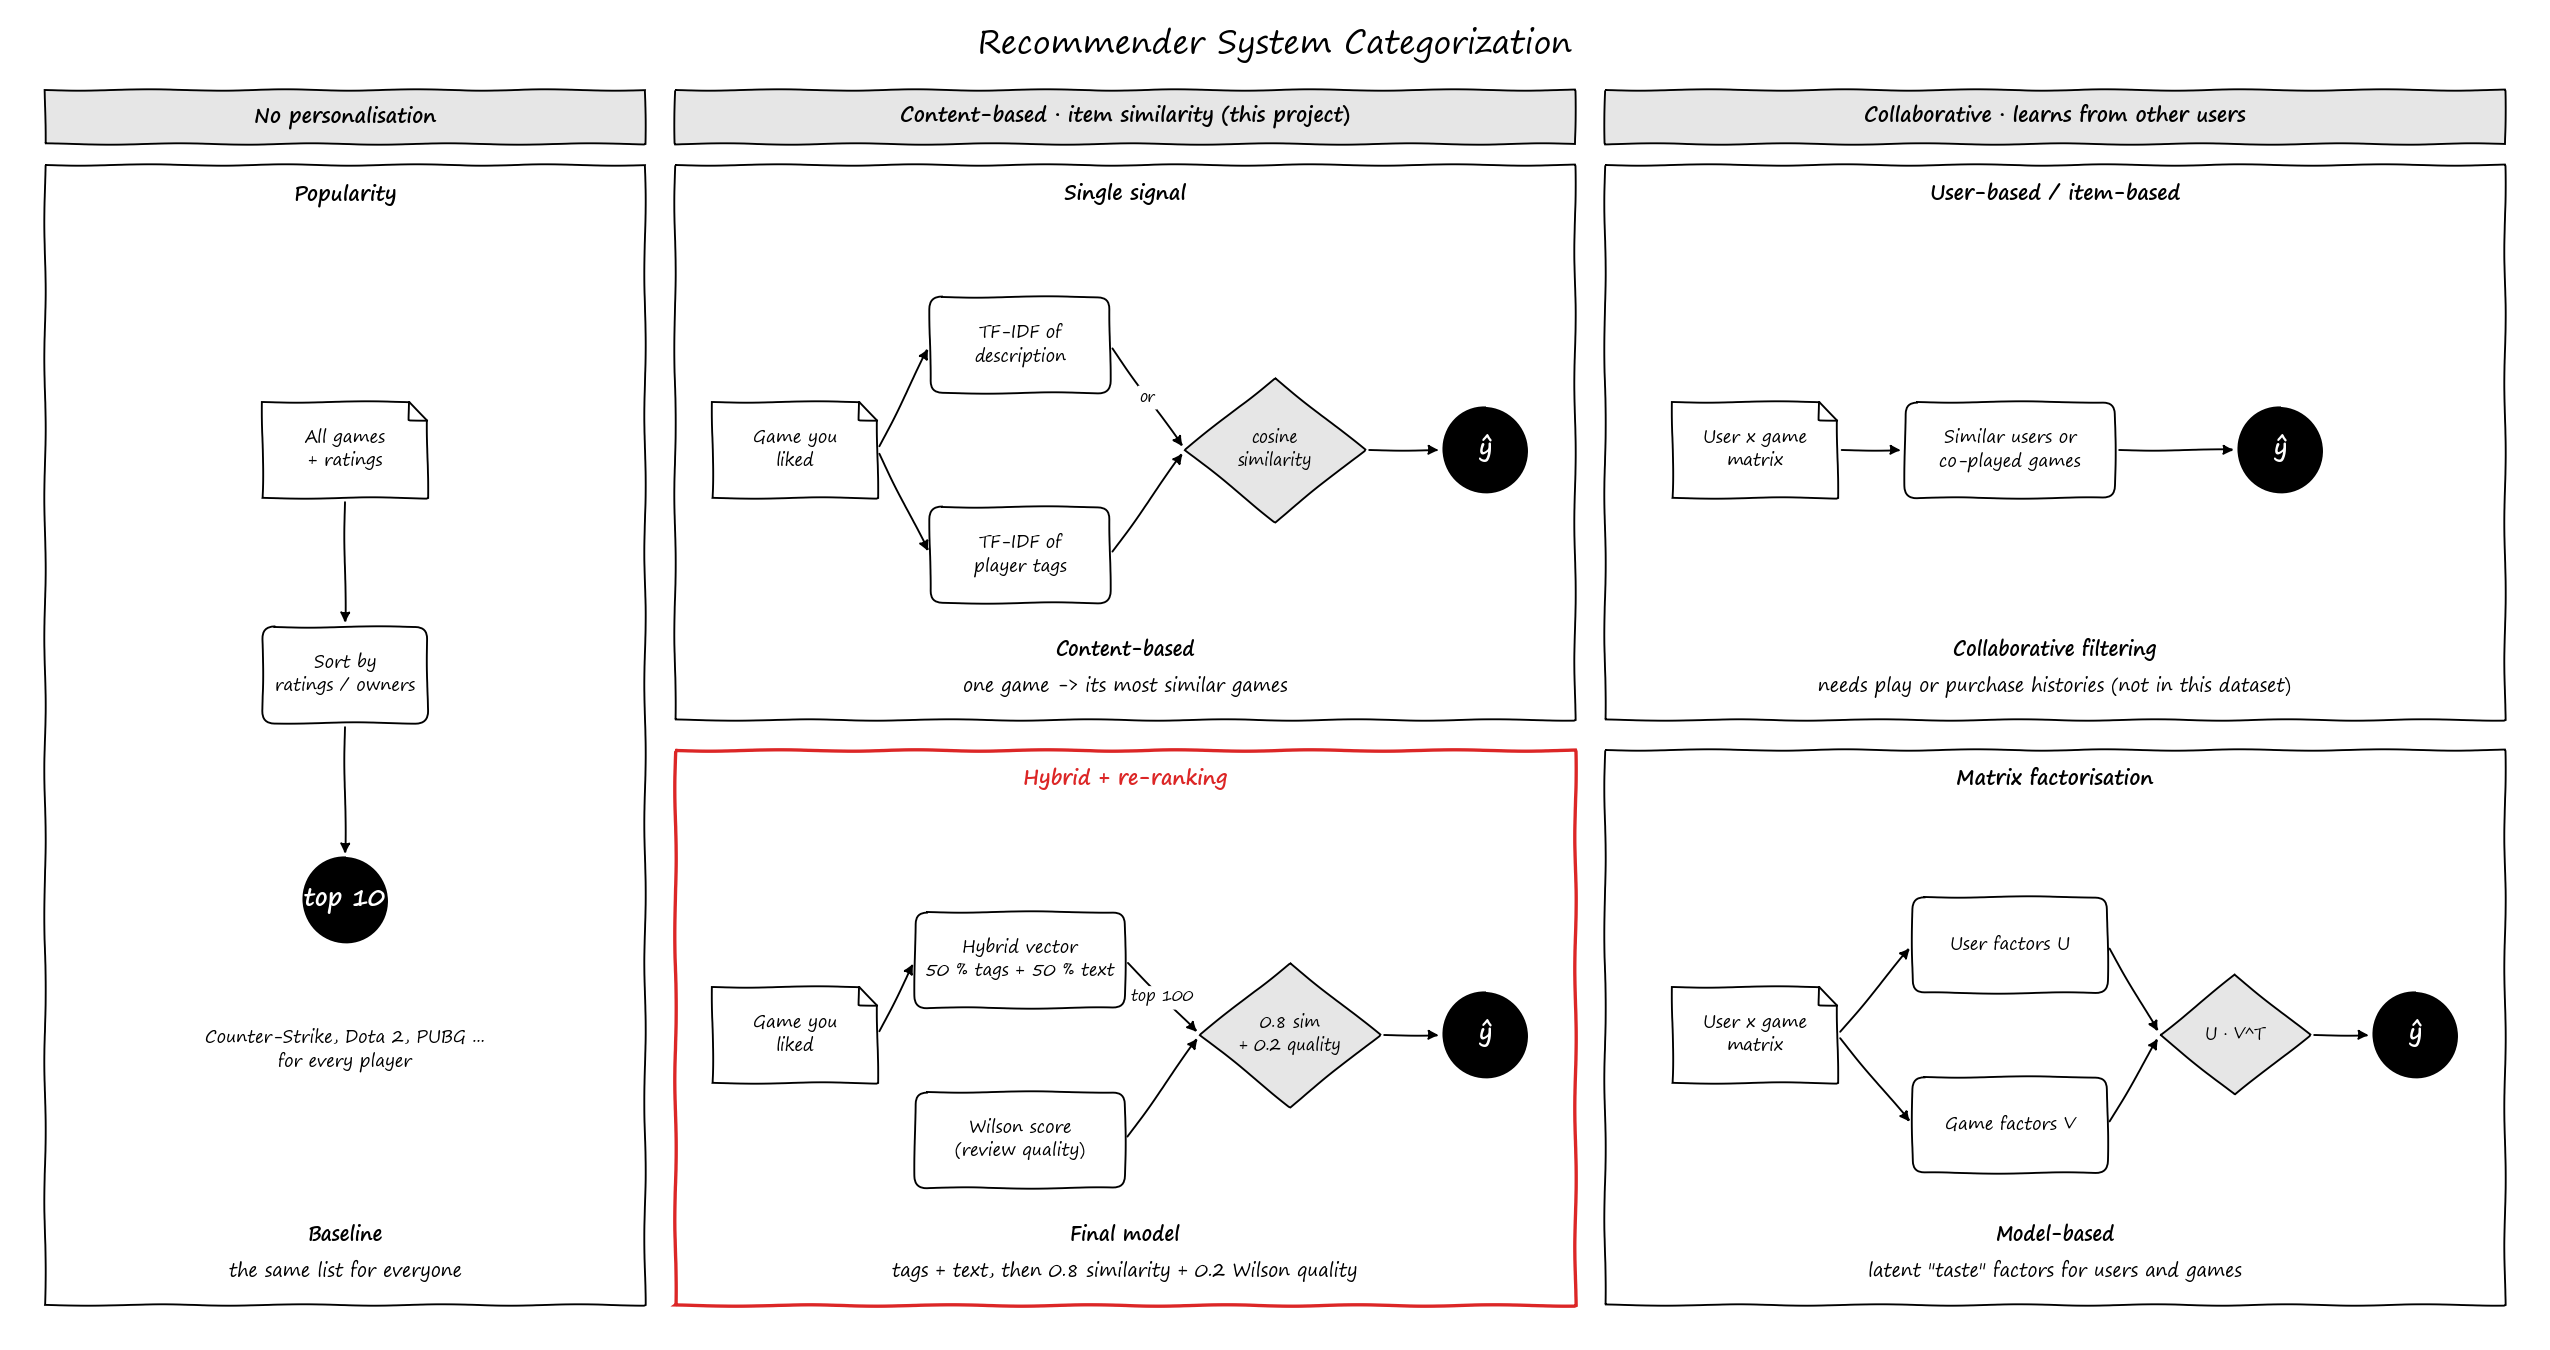

**Question:** How can recommendations be judged without knowing what users played?

For a query game $q$ and its top-$K$ list $R_q$:
$$\text{Genre precision@K} = \frac{1}{K}\sum_{r \in R_q} \frac{|G_q \cap G_r|}{|G_q \cup G_r|} \qquad \text{Coverage} = \frac{|\bigcup_q R_q|}{N} \qquad \text{ILD} = 1 - \overline{\cos}(r_i, r_j)$$
- **Genre precision** → average Jaccard overlap of the store genres $G$ (set by the developer, not used by the description model)
- **Same developer @K** → share of recommendations from the query's developer: a strong hint the games really are related
- **Coverage** → share of the catalogue that appears in at least one list: a recommender that only shows 200 games is useless for discovery
- **Popularity bias** → median owners (lower band) of the recommended games
- **ILD (intra-list diversity)** → how different the recommended games are from each other, measured on tags
- Analogy → judging a librarian without asking readers: do the suggested books share the shelf, the author, and do they cover more than the bestseller table?

**Answer:** content beats both baselines; tags beat descriptions.
- genre precision: tags / hybrid 0.645, descriptions 0.461, popularity 0.215 (worse than random 0.252)
- descriptions find more sequels (same developer 0.076); popularity covers 11 games
- (!) tags overlap with genres, so their score is partly self-confirming

In [ ]:
eligible = np.flatnonzero(games['ratings'].to_numpy() >= MIN_RATINGS)
queries = rng.choice(eligible, size=min(N_QUERIES, len(eligible)), replace=False)
genre_sets = games['genre_set'].to_numpy()
developers = games['developer'].fillna('').to_numpy()
owners_low = games['owners_low'].to_numpy()
quality = games['wilson'].to_numpy()

w = HYBRID_WEIGHT
X_hybrid = sparse.hstack([np.sqrt(w) * X_tags, np.sqrt(1 - w) * X_text]).tocsr()   # cos = w*cos_tags + (1-w)*cos_text
REPRESENTATIONS = {'Descriptions (Count)': normalize(X_count), 'Descriptions (TF-IDF)': X_text,
                   'Tags (TF-IDF)': X_tags, f'Hybrid (tags {w:.0%} + text)': X_hybrid}


def recommend_scores(X, rows):
    return np.asarray(linear_kernel(X[rows], X), dtype=np.float32)


def top_k(scores, rows, k=TOP_K):
    scores = scores.copy()
    scores[np.arange(len(rows)), rows] = -np.inf               # never recommend the query itself
    part = np.argpartition(-scores, k, axis=1)[:, :k]
    order = np.argsort(-np.take_along_axis(scores, part, axis=1), axis=1)
    return np.take_along_axis(part, order, axis=1)


def jaccard(a, b):
    return len(a & b) / len(a | b) if (a or b) else 0.0


def evaluate(name, lists):
    gp = np.mean([np.mean([jaccard(genre_sets[q], genre_sets[r]) for r in rec]) for q, rec in zip(queries, lists)])
    dev = np.mean([np.mean([developers[r] == developers[q] and developers[q] != '' for r in rec]) for q, rec in zip(queries, lists)])
    ild = np.mean([1 - (lambda s: (s.sum() - len(rec)) / (len(rec) * (len(rec) - 1)))(
        (X_tags[rec] @ X_tags[rec].T).toarray()) for rec in lists])
    return {'recommender': name, 'genre precision@10': gp, 'same developer@10': dev,
            'coverage': len(np.unique(lists)) / len(games), 'median owners (low band)': int(np.median(owners_low[lists])),
            'mean Wilson': float(np.mean(quality[lists])), 'diversity (ILD)': ild}


lists_by_model, rows_out = {}, []
pop_order = np.argsort(-games['ratings'].to_numpy())
lists_by_model['Popularity (most rated)'] = np.array([[g for g in pop_order[:TOP_K + 1] if g != q][:TOP_K] for q in queries])
lists_by_model['Random'] = np.array([rng.choice(np.delete(np.arange(len(games)), q), TOP_K, replace=False) for q in queries])
for i, (name, X) in enumerate(REPRESENTATIONS.items(), 1):
    print(f'[{i}/{len(REPRESENTATIONS)}] {name}')
    lists_by_model[name] = np.vstack([top_k(recommend_scores(X, queries[s:s + BATCH]), queries[s:s + BATCH])
                                      for s in range(0, len(queries), BATCH)])
for name, lists in lists_by_model.items():
    rows_out.append(evaluate(name, lists))
leaderboard = pd.DataFrame(rows_out).set_index('recommender')

In [ ]:
display(leaderboard.round(3))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
for ax, col in zip(axes, ['genre precision@10', 'same developer@10', 'coverage']):
    s = leaderboard[col].sort_values()
    ax.barh(s.index, s.values, color=[PALETTE['flag'] if 'Hybrid' in i else PALETTE['main'] for i in s.index])
    ax.set(title=col)
fig.tight_layout()
save(fig, '08_leaderboard')
plt.show()

# [16/20] Re-ranking by quality

Blend similarity with the Wilson score → recommendations move towards well-reviewed games, and we measure what it costs

**Question:** Can we prefer good games without turning the recommender into a bestseller list?

$$\text{score}(q, r) = (1 - \beta)\,\cos(q, r) + \beta\,\text{Wilson}(r)$$
- $\beta = 0$ → pure similarity; $\beta = 1$ → pure quality ranking (the same list for everyone)
- re-ranking happens inside the 100 most similar games, so a recommendation is always somewhat relevant

**Answer:** yes — at β = 0.2 quality rises 0.605 → 0.799 while genre precision only drops 0.645 → 0.624.
Cost: coverage 42.2 % → 30.8 %.

In [ ]:
HYBRID = f'Hybrid (tags {w:.0%} + text)'
X_best = REPRESENTATIONS[HYBRID]
POOL = 100
rerank_rows = []
for beta in QUALITY_WEIGHTS:
    lists = []
    for s in range(0, len(queries), BATCH):
        rows = queries[s:s + BATCH]
        sim = recommend_scores(X_best, rows)
        pool = top_k(sim, rows, POOL)
        blended = (1 - beta) * np.take_along_axis(sim, pool, axis=1) + beta * quality[pool]
        lists.append(np.take_along_axis(pool, np.argsort(-blended, axis=1)[:, :TOP_K], axis=1))
    rerank_rows.append({'beta': beta, **evaluate(f'beta = {beta}', np.vstack(lists))})
rerank = pd.DataFrame(rerank_rows).drop(columns='recommender').set_index('beta')

In [ ]:
display(rerank.round(3))

# [17/20] Clustering the catalogue

Compress the tag vectors with SVD, run k-means for k = 2 … 20, choose k with the elbow and the silhouette → name each cluster by its top tags

**Question:** How many natural groups of games are there?

$$\text{inertia} = \sum_{i} \lVert x_i - \mu_{c(i)} \rVert^2 \qquad\qquad s(i) = \frac{b(i) - a(i)}{\max\{a(i), b(i)\}}$$
- **Elbow** → inertia always falls as $k$ grows; look for the $k$ after which it falls much more slowly
- **Silhouette** → $a(i)$ = mean distance to its own cluster, $b(i)$ = to the nearest other cluster; +1 = clearly placed, 0 = on a border
- **SVD first** → 371 sparse tag weights become 100 dense dimensions (latent semantic analysis): k-means distances behave better
- **Why not the old features?** → my first version clustered on scaled numbers plus label-encoded developer and publisher ids:
  "developer 4,211 is closer to developer 4,212 than to developer 12" is meaningless, so the clusters were too
- Analogy → sorting a record collection: by genre labels it forms piles; by catalogue number it forms nonsense

**Answer:** no strong natural number: no elbow, silhouette only 0.04 → 0.10. k = 18 is the best above 4 and gives nameable clusters.

In [ ]:
svd = TruncatedSVD(n_components=SVD_COMPONENTS, random_state=SEED)
Z = normalize(svd.fit_transform(X_tags))
sil_idx = rng.choice(len(Z), SILHOUETTE_N, replace=False)
k_rows = []
for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=4, random_state=SEED).fit(Z)
    k_rows.append({'k': k, 'inertia': km.inertia_, 'silhouette': silhouette_score(Z[sil_idx], km.labels_[sil_idx])})
k_table = pd.DataFrame(k_rows).set_index('k')

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
axes[0].plot(k_table.index, k_table['inertia'], marker='o', color=PALETTE['main'])
axes[0].set(title='Elbow: inertia vs k', xlabel='k')
axes[1].plot(k_table.index, k_table['silhouette'], marker='o', color=PALETTE['flag'])
axes[1].set(title='Silhouette vs k', xlabel='k')
fig.tight_layout()
save(fig, '09_choose_k')
plt.show()

In [ ]:
show_block('SVD', {'variance kept by 100 components': f'{svd.explained_variance_ratio_.sum():.1%}'})
display(k_table.round(3).T)

**Question:** What are the clusters?

**Answer:** they read like store shelves: strategy, FPS, shoot-'em-up, RPG, puzzle, horror, visual novel, VR, racing, sports …
Visual novels (0.714) review best, casual / hidden object (0.371) worst; the t-SNE map shows niche islands around a mixed centre.

In [ ]:
N_CLUSTERS = int(k_table['silhouette'].loc[4:].idxmax())          # best silhouette with at least 4 clusters
km = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED).fit(Z)
games['cluster'] = km.labels_
tag_dense = X_tags.toarray()
profiles = []
for c in range(N_CLUSTERS):
    members = games['cluster'] == c
    mean_tags = pd.Series(tag_dense[members.to_numpy()].mean(axis=0), index=TAGS).sort_values(ascending=False)
    top_games = games[members].sort_values('ratings', ascending=False)['name'].head(3).tolist()
    word_lift = np.asarray(X_text[members.to_numpy()].mean(axis=0)).ravel() - np.asarray(X_text.mean(axis=0)).ravel()
    profiles.append({'cluster': c, 'games': int(members.sum()), 'top tags': ', '.join(mean_tags.index[:5]),
                     'distinctive words': ', '.join(vocab[np.argsort(-word_lift)[:5]]),
                     'median Wilson': round(float(games.loc[members, 'wilson'].median()), 3),
                     'best-known games': ' | '.join(top_games)})
profiles = pd.DataFrame(profiles).sort_values('games', ascending=False).set_index('cluster')

map_idx = rng.choice(len(Z), TSNE_N, replace=False)
xy = TSNE(n_components=2, perplexity=40, init='pca', random_state=SEED).fit_transform(Z[map_idx])
fig, ax = plt.subplots(figsize=(11, 8))
cmap = plt.get_cmap('tab20', N_CLUSTERS)
ax.scatter(xy[:, 0], xy[:, 1], c=games['cluster'].to_numpy()[map_idx], cmap=cmap, s=6, alpha=0.7)
for c in range(N_CLUSTERS):
    m = games['cluster'].to_numpy()[map_idx] == c
    if m.sum():
        ax.text(*np.median(xy[m], axis=0), str(c), fontsize=13, weight='bold', ha='center')
ax.set(title=f't-SNE map of {TSNE_N:,} games coloured by cluster (k = {N_CLUSTERS})', xticks=[], yticks=[])
save(fig, '10_cluster_map')
plt.show()

In [ ]:
show_block('Clusters', {'k chosen': N_CLUSTERS, 'silhouette (all-k best)': f"k = {int(k_table['silhouette'].idxmax())}"})
pd.set_option('display.max_colwidth', 90)
display(profiles)

# [18/20] Recommendations in action

Ask the final recommender (hybrid, quality-aware) for five well-known games → read the lists like a player would

In [ ]:
BEST_BETA = 0.2


def find_game(title):
    exact = games.index[games['name'].str.lower() == title.lower()]
    if len(exact):
        return games.loc[exact, 'ratings'].idxmax()
    hits = games[games['name'].str.lower().str.contains(re.escape(title.lower()))]
    return hits['ratings'].idxmax() if len(hits) else None


def recommend(title, k=TOP_K, beta=BEST_BETA):
    q = find_game(title)
    sim = recommend_scores(X_best, np.array([q]))
    pool = top_k(sim, np.array([q]), POOL)[0]
    blended = (1 - beta) * sim[0, pool] + beta * quality[pool]
    picks = pool[np.argsort(-blended)[:k]]
    out = games.loc[picks, ['name', 'developer', 'genres', 'wilson', 'cluster', 'header_image']].copy()
    out.insert(1, 'match score %', np.round(sim[0, picks].astype(float) * 100, 1))
    return games.loc[q, 'name'], out.reset_index(drop=True)


def fetch_image(url):
    try:
        r = requests.get(url, timeout=10)
        r.raise_for_status()
        return Image.open(io.BytesIO(r.content)).convert('RGB')
    except Exception:
        return None


def show_cards(title, recs, name=None):
    """Header-image cards with match score, as in my first version (needs Internet; skipped offline)."""
    with ThreadPoolExecutor(10) as pool:
        imgs = list(pool.map(fetch_image, recs['header_image'].fillna('')))
    if not any(imgs):
        print('(!) Header images could not be downloaded (Internet off?) -> table only')
        return
    fig, axes = plt.subplots(2, 5, figsize=(22, 8.5))
    for ax, (_, row), img in zip(axes.ravel(), recs.iterrows(), imgs):
        if img is not None:
            ax.imshow(img)
        ax.set_title(f"{row['name'][:32]}\nmatch {row['match score %']:.1f} % | Wilson {row['wilson']:.2f}\n{str(row['genres'])[:38]}", fontsize=10)
        ax.set(xticks=[], yticks=[])
    fig.suptitle(f'Because you liked {title}  (average match {recs["match score %"].mean():.1f} %)', fontsize=15, weight='bold')
    fig.tight_layout()
    if name:
        save(fig, name)
    plt.show()


for i, title in enumerate(EXAMPLE_GAMES):
    name, recs = recommend(title)
    print(f'\nBecause you liked {name}:')
    display(recs.drop(columns='header_image').head(TOP_K).round(3))

In [ ]:
show_cards(*recommend(EXAMPLE_GAMES[0]), name='11_recommendation_cards')
show_cards(*recommend(EXAMPLE_GAMES[2]))

**Question:** Do the lists make sense to a player?

**Answer:** mostly yes.
- Dark Souls III → other Dark Souls, Skyrim · Cities: Skylines → Parkitect, SimCity 4 · Stardew Valley → Portia, Forager
- Portal 2 → Portal, then shooters: shared first-person / co-op tags outweigh "puzzle"

# [19/20] Deployment: a Gradio app

Wrap the final recommender in a small web app (type a game → table + header images) → set `LAUNCH_APP = True` to get a public link

In [ ]:
def app_recommend(title):
    if not title or find_game(title) is None:
        return pd.DataFrame({'message': [f'No game matching "{title}"']}), []
    name, recs = recommend(title)
    table = recs[['name', 'match score %', 'developer', 'genres', 'wilson']].rename(columns={'wilson': 'quality (Wilson)'}).round(3)
    gallery = [(url, f"{n} | {m:.1f} %") for url, n, m in zip(recs['header_image'], recs['name'], recs['match score %']) if isinstance(url, str)]
    return table, gallery


preview_table, preview_gallery = app_recommend('Stardew Valley')
if LAUNCH_APP:
    try:
        import gradio as gr
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gradio'], check=True)
        import gradio as gr
    demo = gr.Interface(fn=app_recommend, inputs=gr.Textbox(label='Steam game', value='Stardew Valley'),
                        outputs=[gr.Dataframe(label='Similar games'), gr.Gallery(label='Header images', columns=5, height='auto')],
                        title='Steam Game Recommendation System',
                        description='Type a Steam game. Recommendations combine player tags and descriptions, re-ranked by review quality.',
                        examples=[[g] for g in EXAMPLE_GAMES])
    demo.launch(share=True)

In [ ]:
show_block('App', {'launched': LAUNCH_APP, 'preview rows': len(preview_table), 'preview images': len(preview_gallery)})
display(preview_table)

# [20/20] Summary

**Answer:**
- **Data** → long tail; 77 % hidden playtime gaps; attention Gini 0.944
- **What wins** → story, puzzle, soundtrack; what loses → multiplayer, PvP, survival
- **Recommender** → tags beat text (0.645 vs 0.461); re-ranking lifts quality 0.605 → 0.799
- **Next** → collaborative filtering with play data